# Detección de Intrusiones en Redes mediante Aprendizaje Automático (NSL-KDD)

## A. Presentación y Descripción del Problema

* **Dataset elegido:** NSL-KDD (Network Security Laboratory - Knowledge Discovery in Databases).
* **Fuente:** OpenML (`fetch_openml("NSL-KDD")`) / Canadian Institute for Cybersecurity.
* **Tipo de problema:** Clasificación multiclase supervisada.
* **Objetivo:** Clasificar conexiones de red en 5 categorías principales: tráfico legítimo (**Normal**) y cuatro familias de ciberataques (**DoS**, **Probe**, **R2L**, **U2R**), a partir de características de conexión, contenido y tráfico.

### B.2 Vista general, tipos de datos, nulos y duplicados

## B. Carga y Análisis Exploratorio de Datos (EDA)

### B.1 Carga del dataset y agrupación de clases

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

columnas_nsl = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "class", "difficulty_level"
]

try:
    datos = fetch_openml("NSL-KDD", as_frame=True, parser="auto")
    df = datos.frame.copy()
    if "difficulty_level" in df.columns:
        df = df.drop(columns=["difficulty_level"])
except Exception:
    url_train = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"
    url_test = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"
    df_train_raw = pd.read_csv(url_train, names=columnas_nsl)
    df_test_raw = pd.read_csv(url_test, names=columnas_nsl)
    df = pd.concat([df_train_raw, df_test_raw], ignore_index=True).drop(columns=["difficulty_level"])

mapeo_ataques = {
    "normal": "Normal",
    # DoS
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS",
    "smurf": "DoS", "teardrop": "DoS", "mailbomb": "DoS", "apache2": "DoS",
    "processtable": "DoS", "udpstorm": "DoS",
    # Probe
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe",
    "satan": "Probe", "mscan": "Probe", "saint": "Probe",
    # R2L
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L",
    "multihop": "R2L", "phf": "R2L", "spy": "R2L", "warezclient": "R2L",
    "warezmaster": "R2L", "sendmail": "R2L", "named": "R2L",
    "snmpgetattack": "R2L", "snmpguess": "R2L", "xlock": "R2L",
    "xsnoop": "R2L", "worm": "R2L",
    # U2R
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R",
    "rootkit": "U2R", "httptunnel": "U2R", "ps": "U2R",
    "sqlattack": "U2R", "xterm": "U2R"
}

df["class"] = df["class"].astype(str).str.strip().str.rstrip(".").map(mapeo_ataques)

print("Dataset cargado:", df.shape)


Dataset cargado: (148517, 42)


### B.3 Distribución de la variable objetivo (`class`)

,conteo,porcentaje (%)
class,,
Normal,77054,51.88
DoS,53385,35.95
Probe,14077,9.48
R2L,3749,2.52
U2R,252,0.17


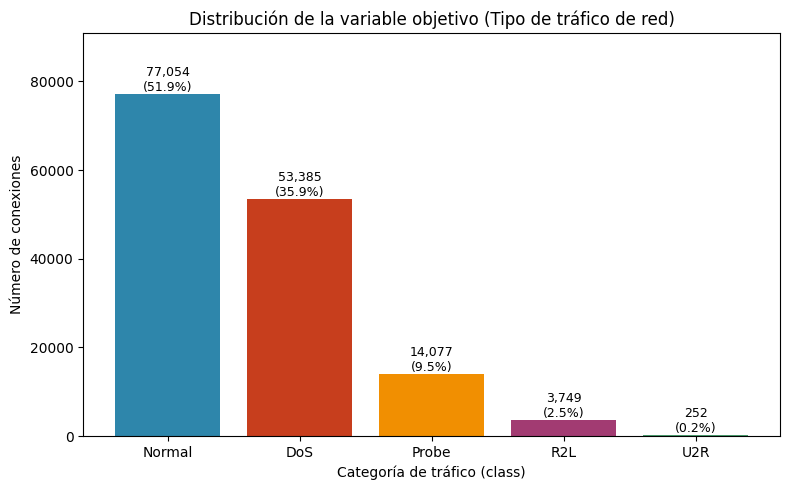

In [ ]:
orden_clases = ["Normal", "DoS", "Probe", "R2L", "U2R"]
conteo = df["class"].value_counts().reindex(orden_clases).dropna().astype(int)
porcentaje = (conteo / len(df)) * 100

resumen_objetivo = pd.DataFrame({
    "conteo": conteo,
    "porcentaje (%)": porcentaje.round(2)
})
display(resumen_objetivo)

fig, ax = plt.subplots(figsize=(8, 5))
colores = ["#2E86AB", "#C73E1D", "#F18F01", "#A23B72", "#4C9F70"]
barras = ax.bar(conteo.index, conteo.values, color=colores)

for barra, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{n:,}\n({p:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title("Distribución de la variable objetivo (Tipo de tráfico de red)")
ax.set_xlabel("Categoría de tráfico (class)")
ax.set_ylabel("Número de conexiones")
ax.set_ylim(0, conteo.max() * 1.18)
plt.tight_layout()
plt.show()

### B.4 Variables categóricas y binarias

In [ ]:
categoricas = ["protocol_type", "service", "flag"]
binarias = [
    "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "root_shell",
    "su_attempted", "num_compromised", "num_root",
    "num_file_creations", "num_shells", "num_access_files",
    "num_outbound_cmds", "is_host_login", "is_guest_login"
]

categoricas = [c for c in categoricas if c in df.columns]
binarias = [b for b in binarias if b in df.columns]

print("Variables categóricas:", len(categoricas), categoricas)
for c in categoricas:
    print(f"\n--- {c} (top 10) ---")
    print(df[c].value_counts(dropna=False).head(10))

print("\nVariables de conteo/indicadores de acceso:", len(binarias))
for b in binarias:
    vals = df[b].value_counts().to_dict()
    print(f"  {b}: {vals}")

Variables categóricas: 3 ['protocol_type', 'service', 'flag']

--- protocol_type (top 10) ---
protocol_type
tcp     121569
udp      17614
icmp      9334
Name: count, dtype: int64

--- service (top 10) ---
service
http        48191
private     26627
domain_u     9937
smtp         8247
ftp_data     7711
other        5197
eco_i        4848
telnet       3979
ecr_i        3829
ftp          2446
Name: count, dtype: int64

--- flag (top 10) ---
flag
SF        89820
S0        36864
REJ       15083
RSTR       3090
RSTO       2335
S1          386
SH          344
S3          298
S2          142
RSTOS0      105
Name: count, dtype: int64

Variables de conteo/indicadores de acceso: 16
  land: {0: 148485, 1: 32}
  wrong_fragment: {0: 147327, 3: 929, 1: 261}
  urgent: {0: 148498, 1: 10, 2: 7, 3: 2}
  hot: {0: 144839, 2: 1883, 1: 459, 28: 277, 30: 258, 4: 193, 6: 146, 5: 87, 24: 68, 3: 66, 19: 58, 22: 57, 18: 48, 14: 30, 7: 14, 20: 9, 15: 5, 11: 4, 10: 3, 9: 2, 25: 2, 44: 2, 77: 1, 17: 1, 12: 1, 8: 1, 

### B.5 Variables numéricas (estadísticas descriptivas y asimetría)

In [ ]:
excluir = set(categoricas + binarias + ["class"])
numericas = [col for col in df.columns if col not in excluir and pd.api.types.is_numeric_dtype(df[col])]

print("Variables numéricas:", len(numericas))
display(df[numericas].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(2))

asimetria = df[numericas].skew().sort_values(ascending=False)
print("\nTop 10 variables numéricas con mayor asimetría:")
print(asimetria.head(10).round(2))

Variables numéricas: 22


,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
count,148517.00,1.485170e+05,1.485170e+05,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,...,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00,148517.00
mean,276.78,4.022795e+04,1.708885e+04,83.34,28.25,0.26,0.26,0.14,0.14,0.67,...,183.93,119.46,0.53,0.08,0.15,0.03,0.26,0.25,0.14,0.14
std,2460.68,5.409612e+06,3.703525e+06,116.76,75.37,0.43,0.43,0.34,0.34,0.44,...,98.53,111.23,0.45,0.19,0.31,0.11,0.43,0.43,0.32,0.34
min,0.00,0.000000e+00,0.000000e+00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.000000e+00,0.000000e+00,2.00,2.00,0.00,0.00,0.00,0.00,0.10,...,87.00,11.00,0.05,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.00,4.400000e+01,0.000000e+00,13.00,7.00,0.00,0.00,0.00,0.00,1.00,...,255.00,72.00,0.60,0.02,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.00,2.780000e+02,5.710000e+02,141.00,17.00,0.85,0.91,0.00,0.00,1.00,...,255.00,255.00,1.00,0.07,0.05,0.01,0.60,0.50,0.00,0.00
99%,8172.00,5.454000e+04,2.559816e+04,511.00,510.00,1.00,1.00,1.00,1.00,1.00,...,255.00,255.00,1.00,1.00,1.00,0.52,1.00,1.00,1.00,1.00
max,57715.00,1.379964e+09,1.309937e+09,511.00,511.00,1.00,1.00,1.00,1.00,1.00,...,255.00,255.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00



Top 10 variables numéricas con mayor asimetría:
dst_bytes                      314.94
src_bytes                      206.68
duration                        12.40
dst_host_srv_diff_host_rate      5.85
srv_count                        4.66
diff_srv_rate                    4.08
dst_host_diff_srv_rate           3.55
srv_diff_host_rate               2.85
dst_host_srv_rerror_rate         2.12
dst_host_rerror_rate             2.11
dtype: float64


### B.6 Gráficos exploratorios clave

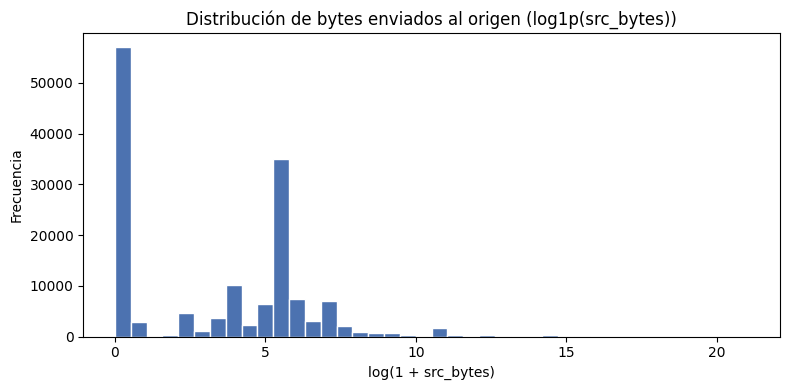


Tabla cruzada protocolo vs clase:


class,DoS,Normal,Probe,R2L,U2R
protocol_type,,,,,
icmp,3553,1402,4375,4,0
tcp,48926,61442,7721,3231,249
udp,906,14210,1981,514,3


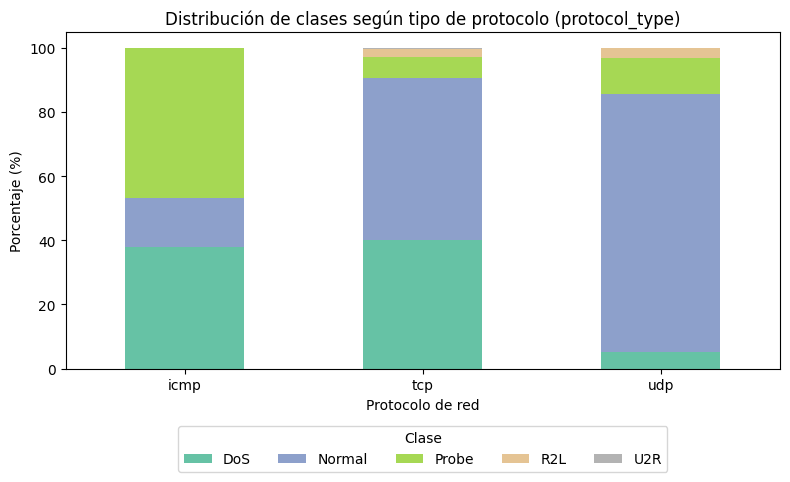

In [ ]:
# B.6.1 Distribución de una variable numérica clave (con escala logarítmica)
fig, ax = plt.subplots(figsize=(8, 4))
valores_src = np.log1p(df["src_bytes"].clip(lower=0))
ax.hist(valores_src, bins=40, color="#4C72B0", edgecolor="white")
ax.set_title("Distribución de bytes enviados al origen (log1p(src_bytes))")
ax.set_xlabel("log(1 + src_bytes)")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# B.6.2 Relación entre variable categórica (protocol_type) y variable objetivo (class)
conteos_proto = pd.crosstab(df["protocol_type"], df["class"])
print("\nTabla cruzada protocolo vs clase:")
display(conteos_proto)

porcentajes_proto = pd.crosstab(df["protocol_type"], df["class"], normalize="index") * 100
ax = porcentajes_proto.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="Set2")
ax.set_title("Distribución de clases según tipo de protocolo (protocol_type)")
ax.set_xlabel("Protocolo de red")
ax.set_ylabel("Porcentaje (%)")
ax.legend(title="Clase", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### B.7 Matriz de correlación en variables numéricas

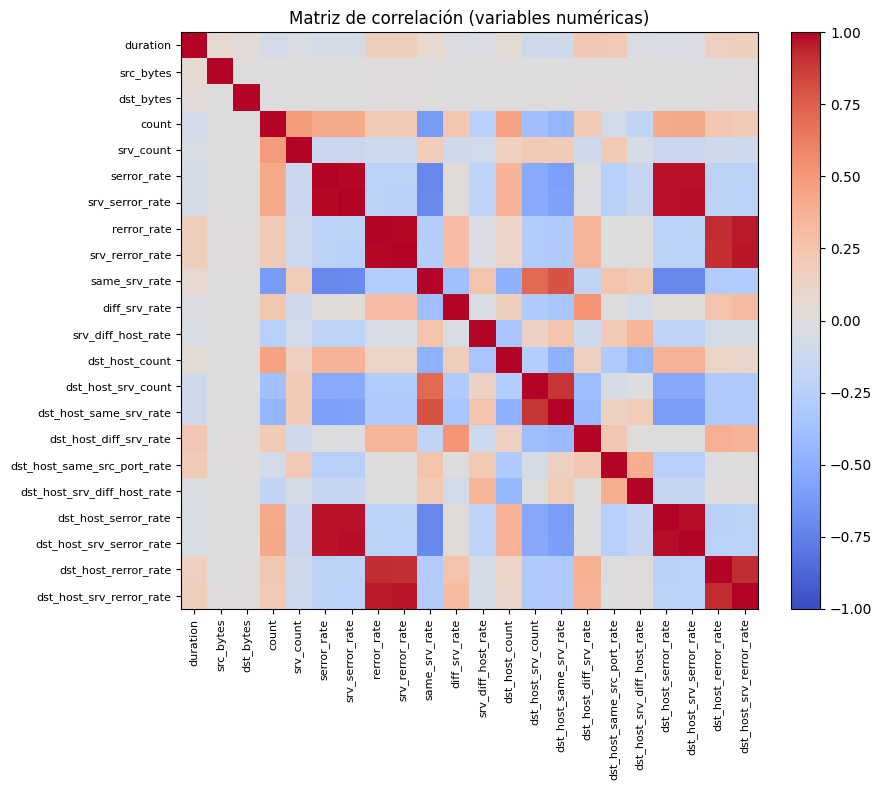

In [ ]:
if len(numericas) > 1:
    corr = df[numericas].corr()
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(numericas)))
    ax.set_yticks(range(len(numericas)))
    ax.set_xticklabels(numericas, rotation=90, fontsize=8)
    ax.set_yticklabels(numericas, fontsize=8)
    ax.set_title("Matriz de correlación (variables numéricas)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

## C. Preprocesamiento de Datos

### C.1 Limpieza, división Train/Test y codificación de la variable objetivo

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df_limpio = df.dropna(subset=["class"]).drop_duplicates().copy()

X = df_limpio.drop(columns=["class"])
y = df_limpio["class"]

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Clases codificadas:", dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")

Clases codificadas: {'DoS': np.int64(0), 'Normal': np.int64(1), 'Probe': np.int64(2), 'R2L': np.int64(3), 'U2R': np.int64(4)}
Train shape: (118310, 41) | Test shape: (29578, 41)


### C.2 Pipeline de transformación (Escalamiento + One-Hot Encoding)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

cols_cat = [c for c in categoricas if c in X_train.columns]
cols_num = [c for c in X_train.columns if c not in cols_cat]

num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocesador = ColumnTransformer(
    transformers=[
        ("num", num_transformer, cols_num),
        ("cat", cat_transformer, cols_cat)
    ]
)

print("Preprocesador configurado correctamente.")

Preprocesador configurado correctamente.


## D. Modelado y Evaluación Comparativa

### D.1 Entrenamiento y comparación de 3 modelos de clasificación

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

modelos = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=150, random_state=42)
}

resultados = []
pipelines_entrenados = {}

for nombre, modelo in modelos.items():
    inicio = time.time()

    clf = Pipeline(steps=[
        ("preprocessor", preprocesador),
        ("classifier", modelo)
    ])

    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    duracion = time.time() - inicio
    pipelines_entrenados[nombre] = clf

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-Score (Weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Tiempo (s)": round(duracion, 2)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by="F1-Score (Macro)", ascending=False)
display(df_resultados.round(4))

,Modelo,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),Tiempo (s)
1,Random Forest,0.9954,0.9809,0.9362,0.9567,0.9953,8.67
2,HistGradientBoosting,0.9927,0.8598,0.9080,0.8730,0.9930,16.08
0,Logistic Regression,0.9462,0.6986,0.9420,0.7487,0.9537,78.18


### D.2 Gráfico comparativo de desempeño entre modelos

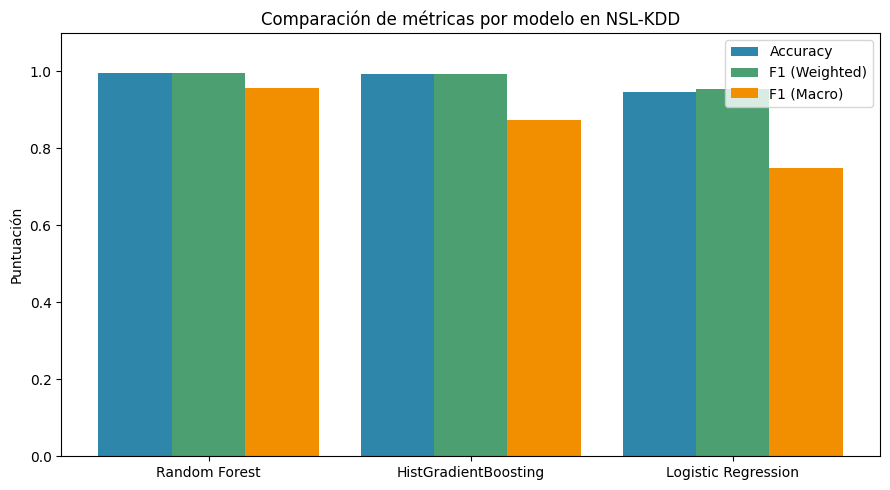

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(df_resultados))
ancho = 0.28

ax.bar(x - ancho, df_resultados["Accuracy"], width=ancho, label="Accuracy", color="#2E86AB")
ax.bar(x, df_resultados["F1-Score (Weighted)"], width=ancho, label="F1 (Weighted)", color="#4C9F70")
ax.bar(x + ancho, df_resultados["F1-Score (Macro)"], width=ancho, label="F1 (Macro)", color="#F18F01")

ax.set_xticks(x)
ax.set_xticklabels(df_resultados["Modelo"])
ax.set_ylim(0, 1.1)
ax.set_ylabel("Puntuación")
ax.set_title("Comparación de métricas por modelo en NSL-KDD")
ax.legend()
plt.tight_layout()
plt.show()

### D.3 Evaluación detallada del mejor modelo (Matriz de Confusión y Reporte)

=== Reporte de Clasificación: Random Forest ===

              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     10597
      Normal       0.99      1.00      1.00     15394
       Probe       1.00      1.00      1.00      2787
         R2L       0.96      0.91      0.93       750
         U2R       0.95      0.78      0.86        50

    accuracy                           1.00     29578
   macro avg       0.98      0.94      0.96     29578
weighted avg       1.00      1.00      1.00     29578



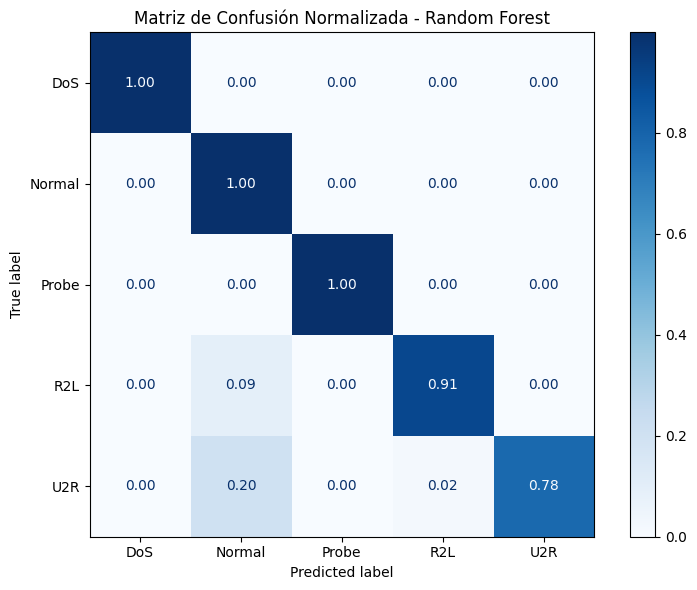

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

mejor_nombre = df_resultados.iloc[0]["Modelo"]
mejor_modelo = pipelines_entrenados[mejor_nombre]
y_pred_best = mejor_modelo.predict(X_test)

print(f"=== Reporte de Clasificación: {mejor_nombre} ===\n")
print(classification_report(y_test, y_pred_best, target_names=le.classes_, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best, normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap="Blues", values_format=".2f", ax=ax)
ax.set_title(f"Matriz de Confusión Normalizada - {mejor_nombre}")
plt.tight_layout()
plt.show()

### D.4 Importancia de características (Feature Importance)

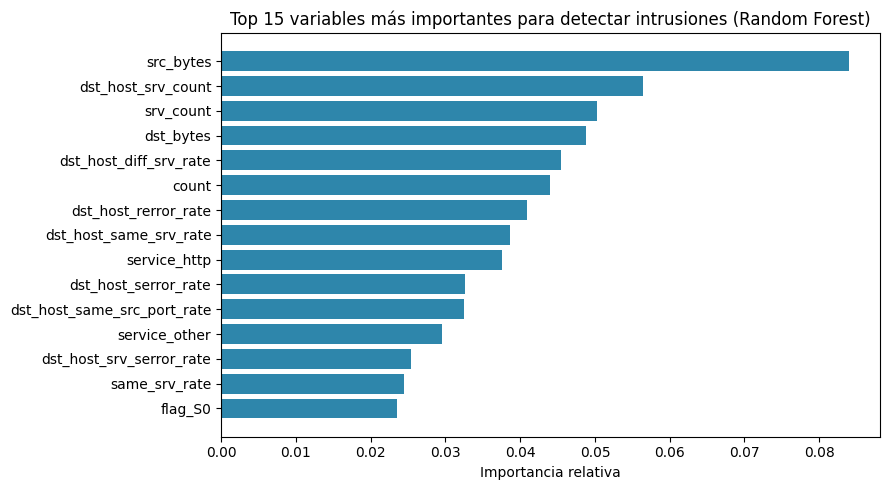

In [ ]:
rf_pipe = pipelines_entrenados["Random Forest"]
nombres_features = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
importancias = rf_pipe.named_steps["classifier"].feature_importances_

df_imp = pd.DataFrame({
    "Feature": [f.replace("num__", "").replace("cat__", "") for f in nombres_features],
    "Importancia": importancias
}).sort_values(by="Importancia", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(df_imp["Feature"][::-1], df_imp["Importancia"][::-1], color="#2E86AB")
ax.set_title("Top 15 variables más importantes para detectar intrusiones (Random Forest)")
ax.set_xlabel("Importancia relativa")
plt.tight_layout()
plt.show()

## E. Conclusiones

1. **Desbalanceo de clases y elección de métricas:** En el dataset **NSL-KDD**, las clases mayoritarias (`Normal` y `DoS`) concentran la mayor parte del tráfico, mientras que ataques complejos como `R2L` y `U2R` representan menos del 1% de las conexiones. Por ello, el **F1-Score Macro** resulta más informativo que el *Accuracy* global para evaluar la capacidad real del sistema de detectar intrusiones críticas poco frecuentes.
2. **Desempeño de modelos:** Los modelos basados en ensambles de árboles (**Random Forest** e **HistGradientBoosting**) superan ampliamente a la **Regresión Logística**, capturando interacciones no lineales entre el protocolo de red, los flags de conexión y el volumen de bytes transferidos (`src_bytes`, `dst_bytes`).
3. **Variables determinantes:** El análisis de importancia de características confirma que el volumen de bytes enviados/recibidos, la tasa de errores de conexión (`serror_rate`), el servicio solicitado (`http`, `private`, `ecr_i`) y el estado de inicio de sesión (`logged_in`) son los indicadores principales para discriminar tráfico legítimo frente a ataques de red.